# 02 · Train the eye-state model

We fine-tune **MobileNetV3-Small** (pretrained on ImageNet) to classify an eye crop as **closed** or **open**.

- Training data: `data/processed/train.npz` (from notebook 01)
- Output: the best model is saved to `models/eye_model.pt`
- Time: about 20 minutes on the RTX 3050 (~55 s per epoch)

Run the cells top to bottom.

## 1. Settings
`TORCH_HOME` makes the pretrained weights download into this project folder instead of the C drive.

In [1]:
import os, time
os.environ["TORCH_HOME"] = "models/torch_cache"

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import kornia.augmentation as K
from torchvision import models
from torchvision.transforms import v2
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

DATA_DIR = "data/processed"
MODEL_PATH = "models/eye_model.pt"
INPUT_SIZE = 128  # eye crops are stored at 64x64 and resized to this before the model
BATCH_SIZE = 128
EPOCHS = 20
LR = 1e-3
CEW_REPEAT = 5   # show each CEW image 5x per epoch
SEED = 42
CLASSES = ["closed", "open"]

torch.manual_seed(SEED)
os.makedirs("models", exist_ok=True)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", torch.cuda.get_device_name(0) if device == "cuda" else "CPU (training will be slow!)")

Device: NVIDIA GeForce RTX 3050 Laptop GPU


## 2. Load the data
CEW (normal camera photos) is only ~5% of the training set, so we repeat it 5 times.
Otherwise the model would mostly learn what infrared eyes look like and do worse on a webcam.

The whole training set (~300 MB) is moved to the GPU once, which makes training much faster.

In [2]:
def load(split):
    d = np.load(os.path.join(DATA_DIR, f"{split}.npz"))
    return d["x"], d["y"], d["src"]

x_train, y_train, src_train = load("train")
x_val, y_val, src_val = load("val")
x_test, y_test, src_test = load("test")

cew = src_train == "cew"
x_train = np.concatenate([x_train] + [x_train[cew]] * (CEW_REPEAT - 1))
y_train = np.concatenate([y_train] + [y_train[cew]] * (CEW_REPEAT - 1))

def to_tensor(x):
    # numpy uint8 (N, 64, 64) -> float tensor (N, 1, 64, 64) on the GPU, pixels 0-1
    return torch.from_numpy(x).unsqueeze(1).to(device).float() / 255

x_train_gpu = torch.from_numpy(x_train).unsqueeze(1).to(device)  # kept as uint8 to save memory
y_train_gpu = torch.from_numpy(y_train).long().to(device)

print(f"train: {len(y_train)} images (after repeating CEW)")
print(f"val:   {len(y_val)} images")
print(f"test:  {len(y_test)} images")

train: 76843 images (after repeating CEW)
val:   13645 images
test:  12872 images


## 3. Augmentation and model input
**Augmentation** randomly changes each training image every time it is used, so the model learns to handle
real webcam conditions. It runs on the GPU (Kornia library), every image in a batch gets its own random changes.

| Change | Simulates |
|---|---|
| Horizontal flip | left vs right eye |
| Rotation, shift, zoom | head tilt, eye crop not perfectly centred |
| Brightness / contrast | room light, night, sunlight |
| Blur, noise | cheap webcam, low light, face far from camera |

`to_model_input` is the **same preprocessing for training, testing and the live webcam app**:
resize, copy gray into 3 channels (the pretrained model expects RGB), and normalize with ImageNet statistics.

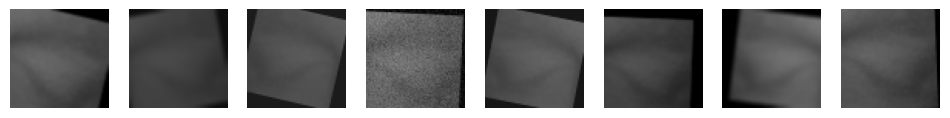

In [3]:
augment = nn.Sequential(
    K.RandomHorizontalFlip(),
    K.RandomAffine(degrees=15, translate=(0.1, 0.1), scale=(0.85, 1.15), p=1.0),
    K.ColorJitter(brightness=0.4, contrast=0.4, p=1.0),
    K.RandomGaussianBlur((5, 5), sigma=(0.1, 2.0), p=0.3),
    K.RandomGaussianNoise(std=0.03, p=0.2),
)

MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]  # ImageNet statistics

def to_model_input(x):
    # x: float tensor (N, 1, 64, 64), pixels 0-1 -> normalized tensor (N, 3, INPUT_SIZE, INPUT_SIZE)
    x = F.interpolate(x, size=(INPUT_SIZE, INPUT_SIZE), mode="bilinear", align_corners=False)
    x = torch.cat([x, x, x], dim=1)
    return v2.functional.normalize(x, MEAN, STD)

# Preview: one eye, augmented 8 different ways
sample = to_tensor(x_train[:1]).repeat(8, 1, 1, 1)
fig, axes = plt.subplots(1, 8, figsize=(12, 1.8))
for ax, img in zip(axes, augment(sample).cpu()):
    ax.imshow(img[0], cmap="gray", vmin=0, vmax=1)
    ax.axis("off")
plt.show()

## 4. Build the model
MobileNetV3-Small with ImageNet weights. We only replace the last layer: 1000 ImageNet classes → 2 classes (closed / open).
Then the whole network is fine-tuned on eye images.

In [4]:
model = models.mobilenet_v3_small(weights=models.MobileNet_V3_Small_Weights.IMAGENET1K_V1)
model.classifier[3] = nn.Linear(model.classifier[3].in_features, 2)
model = model.to(device)

print(f"Parameters: {sum(p.numel() for p in model.parameters()) / 1e6:.2f} M")

Downloading: "https://download.pytorch.org/models/mobilenet_v3_small-047dcff4.pth" to models/torch_cache\hub\checkpoints\mobilenet_v3_small-047dcff4.pth


100.0%


Parameters: 1.52 M


## 5. Train
- **Loss**: cross-entropy with label smoothing (keeps the model from being over-confident, so its probabilities are more reliable for the alarm)
- **Optimizer**: AdamW
- **Learning rate**: short warm-up, then smoothly decreases (one-cycle schedule)

After each epoch we check accuracy on the validation people, separately for MRL and CEW.
The model with the best average of the two is saved.

In [5]:
@torch.no_grad()
def predict(model, x):
    # returns the probability of "open" for each image
    model.eval()
    probs = []
    for i in range(0, len(x), 512):
        xb = to_model_input(to_tensor(x[i:i + 512]))
        probs.append(model(xb).softmax(dim=1)[:, 1].cpu())
    return torch.cat(probs).numpy()

def accuracy(probs, y):
    return ((probs > 0.5) == y).mean()

steps_per_epoch = len(y_train_gpu) // BATCH_SIZE
criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
optimizer = torch.optim.AdamW(model.parameters(), lr=LR)
scheduler = torch.optim.lr_scheduler.OneCycleLR(optimizer, max_lr=LR, total_steps=EPOCHS * steps_per_epoch)

history = {"loss": [], "val_mrl": [], "val_cew": []}
best_score = 0

for epoch in range(1, EPOCHS + 1):
    start = time.time()
    model.train()
    total_loss = 0
    order = torch.randperm(len(y_train_gpu), device=device)  # shuffle every epoch
    for step in range(steps_per_epoch):
        idx = order[step * BATCH_SIZE:(step + 1) * BATCH_SIZE]
        xb = to_model_input(augment(x_train_gpu[idx].float() / 255))
        loss = criterion(model(xb), y_train_gpu[idx])
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        scheduler.step()
        total_loss += loss.item()

    probs = predict(model, x_val)
    acc_mrl = accuracy(probs[src_val == "mrl"], y_val[src_val == "mrl"])
    acc_cew = accuracy(probs[src_val == "cew"], y_val[src_val == "cew"])
    history["loss"].append(total_loss / steps_per_epoch)
    history["val_mrl"].append(acc_mrl)
    history["val_cew"].append(acc_cew)

    saved = ""
    if (acc_mrl + acc_cew) / 2 > best_score:
        best_score = (acc_mrl + acc_cew) / 2
        torch.save(model.state_dict(), MODEL_PATH)
        saved = "  <- saved"
    print(f"epoch {epoch:2d}/{EPOCHS} | loss {history['loss'][-1]:.4f} | "
          f"val MRL {acc_mrl:.4f} | val CEW {acc_cew:.4f} | {time.time() - start:.0f}s{saved}")

epoch  1/20 | loss 0.3387 | val MRL 0.9495 | val CEW 0.9418 | 58s  <- saved
epoch  2/20 | loss 0.2515 | val MRL 0.9666 | val CEW 0.9640 | 60s  <- saved
epoch  3/20 | loss 0.2377 | val MRL 0.9673 | val CEW 0.9668 | 61s  <- saved
epoch  4/20 | loss 0.2307 | val MRL 0.9684 | val CEW 0.9612 | 81s
epoch  5/20 | loss 0.2295 | val MRL 0.9658 | val CEW 0.9695 | 88s  <- saved
epoch  6/20 | loss 0.2266 | val MRL 0.9552 | val CEW 0.9709 | 78s
epoch  7/20 | loss 0.2249 | val MRL 0.9642 | val CEW 0.9695 | 75s
epoch  8/20 | loss 0.2241 | val MRL 0.9483 | val CEW 0.9751 | 72s
epoch  9/20 | loss 0.2213 | val MRL 0.9663 | val CEW 0.9751 | 70s  <- saved
epoch 10/20 | loss 0.2204 | val MRL 0.9577 | val CEW 0.9737 | 66s
epoch 11/20 | loss 0.2177 | val MRL 0.9691 | val CEW 0.9654 | 65s
epoch 12/20 | loss 0.2170 | val MRL 0.9686 | val CEW 0.9792 | 76s  <- saved
epoch 13/20 | loss 0.2145 | val MRL 0.9735 | val CEW 0.9751 | 66s  <- saved
epoch 14/20 | loss 0.2137 | val MRL 0.9666 | val CEW 0.9709 | 76s
epoch 

## 6. Training curves
Loss should go down; validation accuracy should go up and then level off.

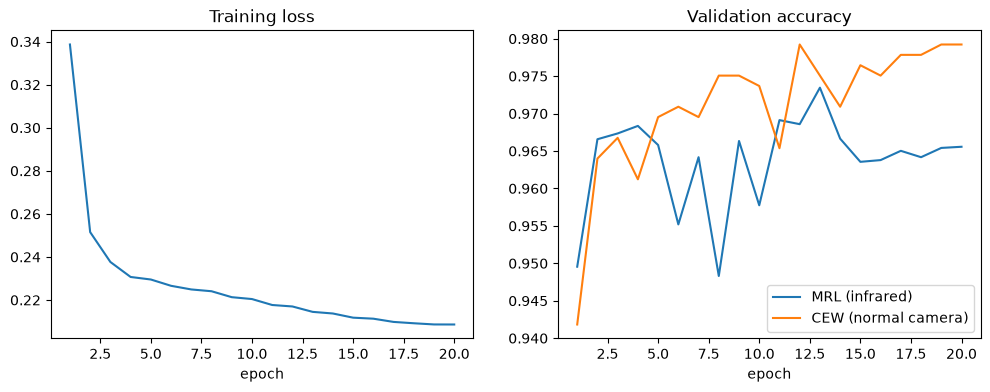

In [6]:
epochs = range(1, EPOCHS + 1)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(epochs, history["loss"])
ax1.set_title("Training loss")
ax1.set_xlabel("epoch")
ax2.plot(epochs, history["val_mrl"], label="MRL (infrared)")
ax2.plot(epochs, history["val_cew"], label="CEW (normal camera)")
ax2.set_title("Validation accuracy")
ax2.set_xlabel("epoch")
ax2.legend()
plt.show()

## 7. Final test
Load the best saved model and score it on the **test set**: people and photos it has never seen.
For drowsiness, **recall of "closed"** matters most: how many closed eyes the model actually catches.

========== MRL test set (12152 images) ==========
              precision    recall  f1-score   support

      closed     0.9355    0.9894    0.9617      6307
        open     0.9878    0.9264    0.9561      5845

    accuracy                         0.9591     12152
   macro avg     0.9617    0.9579    0.9589     12152
weighted avg     0.9607    0.9591    0.9590     12152

========== CEW test set (720 images) ==========
              precision    recall  f1-score   support

      closed     0.9647    0.9773    0.9710       308
        open     0.9828    0.9733    0.9780       412

    accuracy                         0.9750       720
   macro avg     0.9738    0.9753    0.9745       720
weighted avg     0.9751    0.9750    0.9750       720

Overall test accuracy: 0.9600


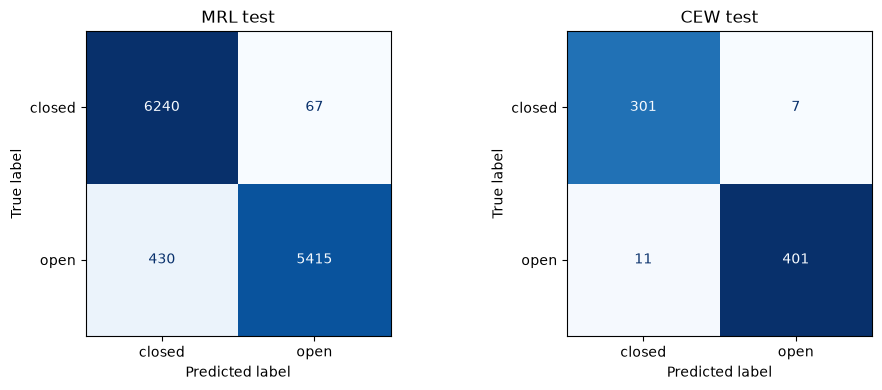

In [7]:
model.load_state_dict(torch.load(MODEL_PATH))
probs_test = predict(model, x_test)
pred_test = (probs_test > 0.5).astype(int)

for name in ["mrl", "cew"]:
    m = src_test == name
    print(f"========== {name.upper()} test set ({m.sum()} images) ==========")
    print(classification_report(y_test[m], pred_test[m], target_names=CLASSES, digits=4))
print(f"Overall test accuracy: {(pred_test == y_test).mean():.4f}")

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, name in zip(axes, ["mrl", "cew"]):
    m = src_test == name
    ConfusionMatrixDisplay.from_predictions(y_test[m], pred_test[m], display_labels=CLASSES,
                                            ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(f"{name.upper()} test")
plt.tight_layout()
plt.show()

## 8. Mistakes
Some test images the model got wrong. The number is the model's probability of "open".
Many mistakes are usually half-closed eyes or unclear images.

515 wrong out of 12872


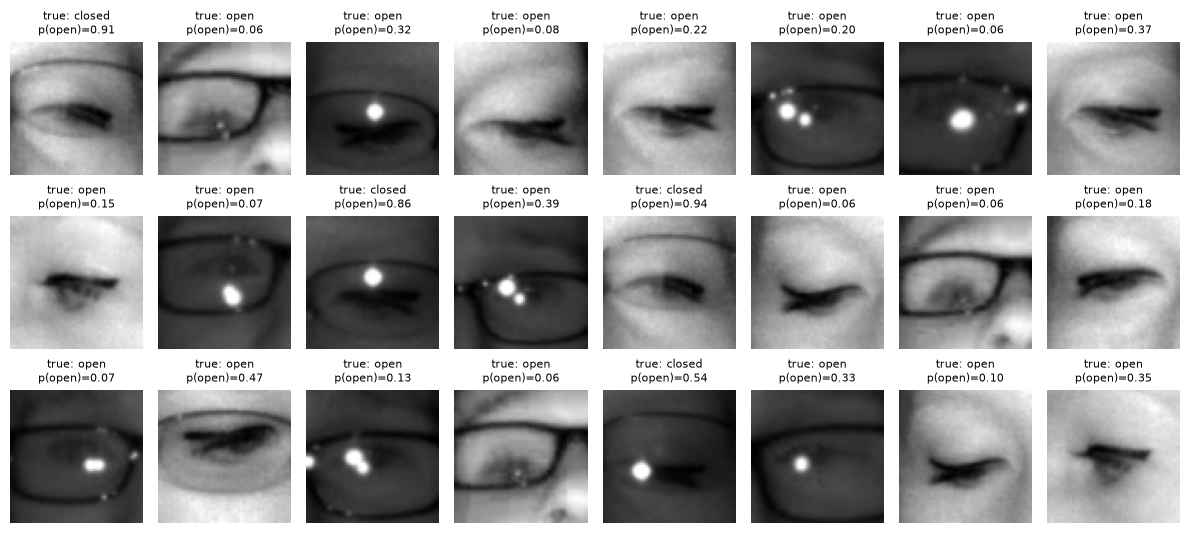

In [8]:
wrong = np.where(pred_test != y_test)[0]
print(f"{len(wrong)} wrong out of {len(y_test)}")

show = np.random.default_rng(SEED).choice(wrong, min(24, len(wrong)), replace=False)
fig, axes = plt.subplots(3, 8, figsize=(12, 5.5))
for ax in axes.flat:
    ax.axis("off")
for ax, i in zip(axes.flat, show):
    ax.imshow(x_test[i], cmap="gray")
    ax.set_title(f"true: {CLASSES[y_test[i]]}\np(open)={probs_test[i]:.2f}", fontsize=8)
plt.tight_layout()
plt.show()

✅ Done. The trained model is in `models/eye_model.pt`. Next: **03_live_detection.ipynb**